# Problema 1 — Estimador de Máxima Verosimilitud (MLE)

Estimación por máxima verosimilitud del parámetro $\theta$ de la densidad $f_X(x)=\frac{1}{2}(1+\theta x)$, con $|x|<1$ y $\theta \in [-1,1]$. El MLE se obtiene numéricamente y se estudia su sesgo, varianza y error cuadrático medio para muestras de tamaño 10, 100 y 1000.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar

## 1. Simulación con $\theta = -1/3$

In [2]:
def simular_theta(n, theta=-1 / 3, seed=None):
    rng = np.random.default_rng(seed)
    muestra = []
    while len(muestra) < n:
        x = rng.uniform(-1, 1, size=n)
        u = rng.uniform(0, 1, size=n)
        aceptar = u <= 0.5 * (1 + theta * x)  # el máximo de f es 1, aceptamos x si u≤f(x)
        muestra.extend(x[aceptar])
    return np.array(muestra[:n])


x = simular_theta(10, theta=-1 / 3, seed=42)
print(x)

[ 0.5479121  -0.8116453   0.9512447   0.57212861  0.94139605 -0.61072258
 -0.06655799 -0.91239247 -0.69142102 -0.12569616]


## 2. Log-verosimilitud y máximo para $n = 10$

La función de log-verosimilitud es

$$\ell(\theta) = \sum_{i=1}^{n} \log\!\left( \frac{1}{2}(1+\theta x_i) \right)$$

y su máximo $\hat{\theta}$ se obtiene numéricamente.

θ̂ = -0.0429


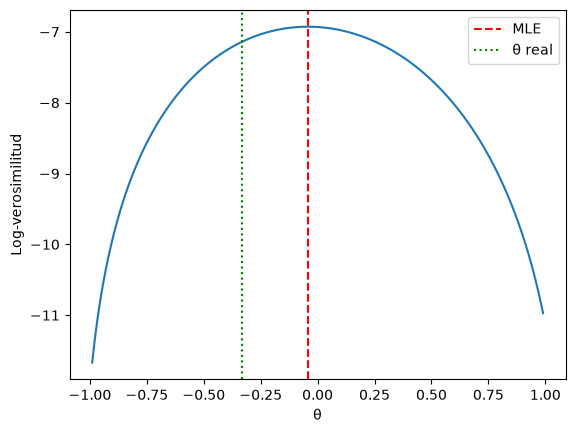

In [3]:
def loglik(theta, x):
    if theta <= -1 or theta >= 1:
        return -np.inf
    vals = 1 + theta * x
    if np.any(vals <= 0):
        return -np.inf
    return np.sum(np.log(0.5) + np.log(vals))


def estimar_theta(x):
    res = minimize_scalar(
        lambda th: -loglik(th, x),  # negativo de la función, queremos el máximo
        bounds=(-0.999999, 0.999999),  # [-1, 1], evitamos problemas numéricos
        method='bounded'
    )
    return res.x


theta_hat = estimar_theta(x)
print(f"θ̂ = {theta_hat:.4f}")

thetas = np.linspace(-0.99, 0.99, 400)
ll = [loglik(t, x) for t in thetas]

plt.plot(thetas, ll)
plt.axvline(theta_hat, color='red', linestyle='--', label='MLE')
plt.axvline(-1 / 3, color='green', linestyle=':', label='θ real')
plt.xlabel('θ')
plt.ylabel('Log-verosimilitud')
plt.legend()
plt.show()

## 3. Sesgo, varianza y MSE del MLE ($B = 50$ repeticiones)

In [4]:
def simular_estimaciones(n, B=50, theta_true=-1 / 3, seed=123):
    rng = np.random.default_rng(seed)
    est = []
    for b in range(B):
        x = simular_theta(n, theta=theta_true, seed=rng.integers(1_000_000_000))
        est.append(estimar_theta(x))
    est = np.array(est)
    sesgo = est.mean() - theta_true
    var = est.var(ddof=1)
    mse = np.mean((est - theta_true) ** 2)
    return est, sesgo, var, mse

filas = []
for n in [10, 100, 1000]:
    est, sesgo, var, mse = simular_estimaciones(n, B=50)
    filas.append({"n": n, "θ̂ promedio": est.mean(), "sesgo": sesgo,
                  "varianza": var, "MSE": mse})

tabla = pd.DataFrame(filas).set_index("n").round(4)
tabla


,θ̂ prom.,sesgo,varianza,MSE
n,,,,
10,-0.3212,0.0121,0.3163,0.3101
100,-0.3025,0.0308,0.0249,0.0254
1000,-0.3446,-0.0112,0.0026,0.0027


## Conclusiones

- Overleaf (modo edición): https://www.overleaf.com/4334438197ngbkydwtbsmf#09bc77
- Overleaf (modo lectura): https://www.overleaf.com/read/tmkfqdfvmsjz#085dfd